# 02 — Preprocessing & Augmentation

**Workstream:** Disease Detection · **Batch 4 (Day 4-5)** · **Status: IMPLEMENTED**

Visual proof that `ai/disease_detection/src/transforms.py` does what it claims: train-time augmentation
(random crop/flip/rotation/color-jitter) vs. eval-time deterministic preprocessing (resize + center-crop),
both normalized to ImageNet stats to match the MobileNetV2 backbone (ADR-003).

In [1]:
import sys
from pathlib import Path
_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ai" / "common" / "config.py").exists())
sys.path.insert(0, str(_root))
import matplotlib.pyplot as plt
from PIL import Image
from ai.disease_detection.src.transforms import train_transform, eval_transform
import torch

sample_path = next((_root / "data/raw/disease_images/plantvillage_subset").glob("Tomato___healthy/*.JPG"))
img = Image.open(sample_path).convert("RGB")
print("Original size:", img.size)

Original size: (256, 256)


## Train-time augmentation — same source image, 6 random draws

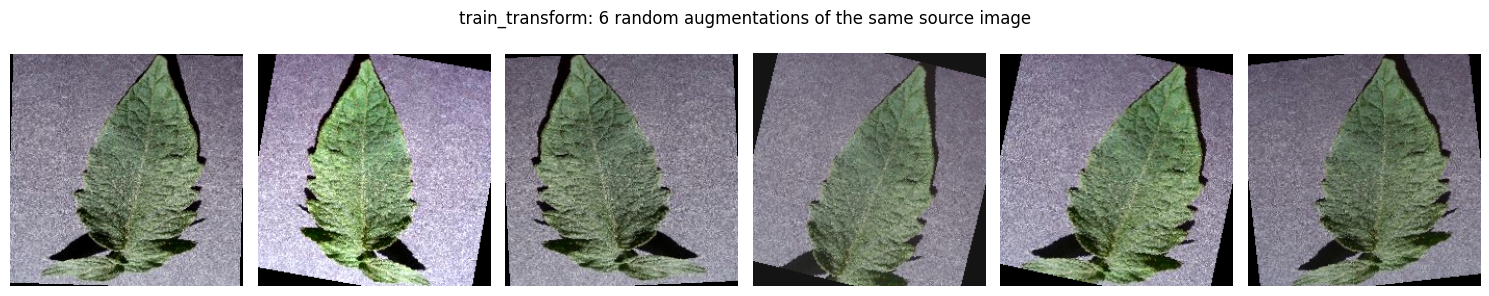

In [2]:
def unnormalize(t):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (t * std + mean).clamp(0, 1)

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax in axes:
    aug = train_transform(img)
    ax.imshow(unnormalize(aug).permute(1, 2, 0).numpy())
    ax.axis("off")
plt.suptitle("train_transform: 6 random augmentations of the same source image")
plt.tight_layout()
plt.show()

## Eval-time preprocessing — deterministic, always identical

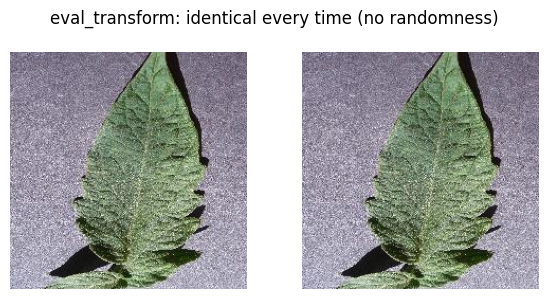

eval_transform is deterministic: True


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
for ax in axes:
    ev = eval_transform(img)
    ax.imshow(unnormalize(ev).permute(1, 2, 0).numpy())
    ax.axis("off")
plt.suptitle("eval_transform: identical every time (no randomness)")
plt.tight_layout()
plt.show()

t1, t2 = eval_transform(img), eval_transform(img)
print("eval_transform is deterministic:", torch.equal(t1, t2))

## Next: `03_baseline_cnn.ipynb`

**Status: IMPLEMENTED.** Both transform pipelines run and visually verified above.